In [1]:
# Repo-root bootstrap: find the directory containing the `llm_perf` package
# (walking up from CWD) and chdir there so paths like "llm_perf/database/..."
# and "assets/..." resolve regardless of where the notebook lives on disk.
import os
from pathlib import Path
_p = Path.cwd()
while not (_p / "llm_perf" / "__init__.py").exists():
    if _p == _p.parent:
        raise RuntimeError("Could not find the llm_perf repository root above the current directory")
    _p = _p.parent
os.chdir(_p)
print("Working directory: repository root (the directory that contains llm_perf/)")

Working directory: repository root (the directory that contains llm_perf/)


# Basic Pareto Sweep — the Full Exploration Space

**Question:** where does the (throughput/GPU, interactivity) Pareto frontier come from? What does the underlying point cloud look like — i.e. what's the full space of `(PP, TP, EP, SP, B)` choices that the frontier selects from?

A Pareto study normally plots only the frontier — the upper-right envelope of this cloud — as `pareto_tpu_vs_gb200.ipynb` does. This notebook shows the cloud itself so the frontier-extraction step is visible.

**Setup:** GPT-1.8T MoE @ FP4 on GB200 NVL72 (baseline hardware, no I/O / HBM / overhead sweeps). Enumerate every valid `(PP, TP, EP, SP)` partition, sweep batch `B` from 1 up to the KV-paging max, score each `(partition, B)` evaluation, then extract the upper-right envelope.

**What's on the plot:**

- **Gray cloud** — every valid `(partition, B)` evaluation in the exploration space.
- **Colored points** — the same cloud, but colored by partition PP (so you can see which shape dominates which region).
- **Bold line + markers** — the extracted Pareto frontier (upper-right envelope).
- **Annotations** — winning `(PP, TP, EP, B)` at a few frontier corners.

The ratio `|frontier| / |cloud|` quantifies how much of the search space is actually useful — most `(partition, B)` evaluations are dominated.

## 1. Imports and spec loading

In [2]:
from __future__ import annotations

import math
from copy import deepcopy
from dataclasses import dataclass

import matplotlib.pyplot as plt

from llm_perf import InferenceCalculator
from llm_perf.core.kv_paging_model import KVPagingConfig, compute_kv_paging
from llm_perf.core.memory_model import compute_memory
from llm_perf.io import load_model_spec, load_system_spec, load_tuning_spec
from llm_perf.specs.partition_spec import PartitionSpec
from llm_perf.specs.framework_spec import FrameworkSpec
from llm_perf.specs.system_spec import span_tiers

MODEL = "llm_perf/database/model/gpt_1_8t_moe.json"
SYSTEM = "llm_perf/database/system/gb200.72gpu.json"
TUNER = "llm_perf/database/tuner/gpt_1_8t_moe.tuner.json"

S_DECODE = 8192
BPP_FP4 = 0.5

model = load_model_spec(MODEL)
model.bytes_per_param = BPP_FP4
system = load_system_spec(SYSTEM)
tuner_base = load_tuning_spec(TUNER)
tuner_base.S_decode = S_DECODE
tuner_base.B_decode = 1

# Algorithm, in-network-collective and overlap knobs live on FrameworkSpec.
# The default is ring algorithms with no compute/comm overlap, and it DOES
# engage in-network collectives where the fabric offers them: on NVL72 the
# tensor-parallel all-reduce runs through the NVLink switch. Set
# inc_enabled=False to price software collectives only.
framework_base = FrameworkSpec.default()

up_alpha, up_bw, _ = span_tiers(system.get_tier_chain('TP'), 2)
print(f"Model: {model.name}  L={model.L}  H={model.H}  n_kv={model.n_kv}  b={model.bytes_per_param}")
print(f"System: {system.num_devices} GPUs  HBM={system.device.hbm_bandwidth_GBps:.0f} GB/s  "
      f"peak={system.device.peak_flops_TF:.0f} TF  "
      f"scale-up={up_bw:.0f} GB/s · {up_alpha:.2f} μs")
print(f"Framework: tp/ep algorithm={framework_base.tp_algorithm_decode}/{framework_base.ep_algorithm_decode}  "
      f"inc_enabled={framework_base.inc_enabled}  kernel_launch={framework_base.kernel_launch_us} μs")


Model: GPT-1.8T-MoE  L=120  H=20480  n_kv=16  b=0.5
System: 72 GPUs  HBM=8000 GB/s  peak=2500 TF  scale-up=900 GB/s · 0.50 μs
Framework: tp/ep algorithm=ring/ring  inc_enabled=True  kernel_launch=1.5 μs


## 2. Partition enumeration

Constraints (from `llm_perf/utils/partition_enum.py` — `describe_constraints` printed below):

- **`PP ≤ 8`** — applied here as an operational cap (see note below). The unbounded `pp_max` default is 32; this notebook pins `pp_max=8` to match the typical PP-capped operational regime where the per-token latency budget and the microbatch floor make deeper PP impractical. PP is chosen from a ladder `[1, 2, 3, 4, 5, 6, 8]` under this cap (no divisibility into `L`).
- `TP ≤ min(n_kv, n_experts)` so each TP rank holds ≥ 1 KV head and ≤ all-expert reach (powers-of-2 ladder).
- `EP ≤ n_experts` (powers-of-2 ladder); `EP = 1` for dense models.
- `TP · EP ≤ scale_up_domain` so the heavy intra-layer collectives stay inside the rack-local NVLink / NVL boundary (NVL72 → 72 ranks at tier 0).
- `SP` sweeps the ladder `[1, 2, 4, 8, 16, 32, 64]`.
- `PP · TP · EP · SP ≤ num_devices` (the cluster-fit cap).

For GPT-1.8T MoE on NVL72: `L = 120`, `n_kv = 16`, `n_experts = 16`, `scale_up = 72` (single-tier NVL fabric). With the PP=8 cap, each PP stage owns `L/PP = 15` layers — substantially heavier per-stage workload than the unbounded case (`L/PP = 3.75` at PP=32).

> **Why the cap?** A token crosses every stage, so pipeline depth does not shorten its path: the time per token is the sum over all `PP` stages. What depth buys is memory — each device holds `1/PP` of the weights and of the KV cache, so a deeper pipeline admits a larger batch — at the price of `PP`× the devices per replica and one inter-stage hop per stage. The `B` sequences circulate as `PP` microbatches of `B/PP`, so deep PP also needs `B ≥ PP` to keep every stage busy. To compare against a deeper-PP frontier, change `PP_MAX` in §2 and re-run.


In [3]:
PP_MAX = 8   # Operational cap; raise to 32 to match unbounded-PP analysis.

from llm_perf.utils import (
    enumerate_partitions as _enumerate_partitions,
    describe_constraints,
)


def enumerate_partitions(num_devices: int) -> list[PartitionSpec]:
    """Local shim around llm_perf.utils.enumerate_partitions; pins (model, system, pp_max).

    Constraints applied: PP <= PP_MAX (set above; default 8 here, vs the
    library's 32);  TP <= min(n_kv, n_experts); EP <= n_experts (or 1 for
    dense); TP*EP <= scale_up_domain_size(system); SP <= 64 (ladder-based);
    PP*TP*EP*SP <= num_devices.
    See `llm_perf/utils/partition_enum.py` for the full derivation.
    """
    return _enumerate_partitions(model, system, num_devices=num_devices, pp_max=PP_MAX)


print(describe_constraints(model, system, pp_max=PP_MAX))

partitions = enumerate_partitions(system.num_devices)
print(f"Valid partitions: {len(partitions)}")
print("First 10:", [f"PP={p.PP} TP={p.TP} EP={p.EP} SP={p.SP}" for p in partitions[:10]])


PP ≤ 8; TP ≤ min(n_kv=16, n_experts=16) = 16; EP ≤ n_experts=16; TP·EP ≤ scale_up=72 (tier_idx=0)
Valid partitions: 260
First 10: ['PP=1 TP=1 EP=1 SP=1', 'PP=1 TP=1 EP=1 SP=2', 'PP=1 TP=1 EP=1 SP=4', 'PP=1 TP=1 EP=1 SP=8', 'PP=1 TP=1 EP=1 SP=16', 'PP=1 TP=1 EP=1 SP=32', 'PP=1 TP=1 EP=1 SP=64', 'PP=1 TP=1 EP=2 SP=1', 'PP=1 TP=1 EP=2 SP=2', 'PP=1 TP=1 EP=2 SP=4']


## 3. Sweep every `(partition, B)` in the exploration space

For each partition we derive `B_max` from the KV paging model (how many concurrent sequences fit in HBM after weights), then sweep log-spaced batch sizes from 1 to `B_max`. Each evaluation produces a point in (tput/GPU, 1/TPOT) space.

In [4]:
@dataclass
class Point:
    partition: PartitionSpec
    B: int
    tput_per_gpu: float
    interactivity: float
    TPOT_ms: float

    @property
    def part_label(self) -> str:
        p = self.partition
        return f"PP={p.PP} TP={p.TP} EP={p.EP} SP={p.SP}"


def log_spaced_batch_sizes(b_max: int) -> list[int]:
    if b_max <= 1:
        return [1]
    n = max(int(math.log10(b_max) * 10), 16)
    raw = {1, b_max}
    for i in range(n + 1):
        raw.add(max(1, int(round(10 ** (i * math.log10(b_max) / n)))))
    p = 1
    while p <= b_max:
        raw.add(p)
        p *= 2
    return sorted(raw)


def sweep_partition(partition: PartitionSpec) -> list[Point]:
    try:
        mem = compute_memory(model, system, partition, tuner_base, framework_base)
    except Exception:
        return []
    paging = KVPagingConfig(block_size=16, beam_width=1, system_overhead_GB=1.5)
    kv = compute_kv_paging(model, system, partition, tuner_base, framework_base, mem, paging)
    b_max = int(kv.max_sequences)
    if b_max < 1:
        return []
    pts: list[Point] = []
    for B in log_spaced_batch_sizes(b_max):
        tuner = deepcopy(tuner_base)
        tuner.B_decode = B
        try:
            r = InferenceCalculator(model, system, partition, tuner, framework_base).run()
        except Exception:
            continue
        if r.latency.TPOT <= 0:
            continue
        pts.append(Point(
            partition=partition,
            B=B,
            tput_per_gpu=r.latency.TTPS / system.num_devices,
            interactivity=1.0 / r.latency.TPOT,
            TPOT_ms=r.latency.TPOT * 1e3,
        ))
    return pts


all_points: list[Point] = []
for part in partitions:
    all_points.extend(sweep_partition(part))

print(f"Total evaluations in the exploration space: {len(all_points)}")
print(f"Distinct partitions with ≥1 feasible B: "
      f"{len({p.part_label for p in all_points})}")

Total evaluations in the exploration space: 6726
Distinct partitions with ≥1 feasible B: 200


## 4. Extract the Pareto frontier

Walk the points in order of decreasing throughput/GPU and keep those that strictly improve interactivity — the upper-right envelope.

In [5]:
def pareto_frontier(points: list[Point]) -> list[Point]:
    sorted_pts = sorted(points, key=lambda p: (-p.tput_per_gpu, -p.interactivity))
    frontier: list[Point] = []
    best_interact = -math.inf
    for p in sorted_pts:
        if p.interactivity > best_interact + 1e-9:
            frontier.append(p)
            best_interact = p.interactivity
    frontier.sort(key=lambda p: p.tput_per_gpu)
    return frontier


frontier = pareto_frontier(all_points)
print(f"Frontier points: {len(frontier)}  ({len(frontier)/len(all_points)*100:.1f}% of cloud)")

# Winner summary
winners: dict[str, int] = {}
for p in frontier:
    winners[p.part_label] = winners.get(p.part_label, 0) + 1
print("\nPartitions appearing on the frontier (count of corner points):")
for k, v in sorted(winners.items(), key=lambda kv: -kv[1]):
    print(f"  {k:30s}  ×{v}")

Frontier points: 41  (0.6% of cloud)

Partitions appearing on the frontier (count of corner points):
  PP=1 TP=16 EP=4 SP=1            ×27
  PP=1 TP=8 EP=8 SP=1             ×8
  PP=1 TP=16 EP=1 SP=1            ×2
  PP=1 TP=4 EP=16 SP=1            ×2
  PP=2 TP=16 EP=1 SP=1            ×1
  PP=1 TP=16 EP=2 SP=1            ×1


## 5. Plot: exploration space + frontier

Two panels side by side:
- **Left:** raw cloud in gray with the frontier overlaid — visualize how small a fraction of the space the frontier occupies.
- **Right:** same cloud, but colored by PP — reveals which partition shape dominates which region of the space.

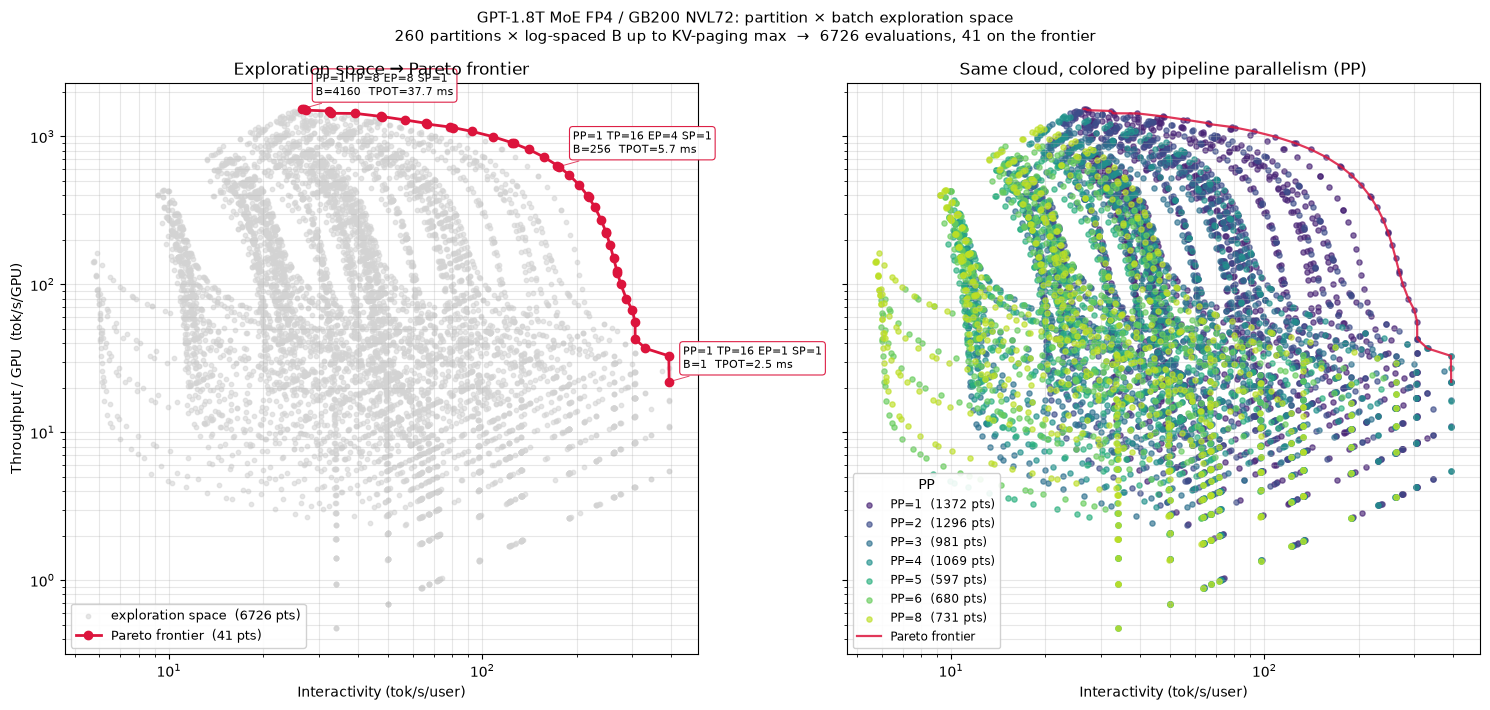

In [6]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 7.2), sharex=True, sharey=True)

xs_all = [p.interactivity for p in all_points]
ys_all = [p.tput_per_gpu for p in all_points]
xs_fr = [p.interactivity for p in frontier]
ys_fr = [p.tput_per_gpu for p in frontier]

# --- Left panel: cloud + frontier ---
axL.scatter(xs_all, ys_all, s=10, color="lightgray", alpha=0.55,
            label=f"exploration space  ({len(all_points)} pts)")
axL.plot(xs_fr, ys_fr, "-o", color="crimson", lw=2.0, ms=6,
         label=f"Pareto frontier  ({len(frontier)} pts)")

# Annotate a handful of frontier corners (evenly spaced along the frontier).
if len(frontier) >= 3:
    idxs = [0, len(frontier) // 2, len(frontier) - 1]
else:
    idxs = list(range(len(frontier)))
for i in idxs:
    p = frontier[i]
    axL.annotate(
        f"{p.part_label}\nB={p.B}  TPOT={p.TPOT_ms:.1f} ms",
        xy=(p.interactivity, p.tput_per_gpu),
        xytext=(10, 10), textcoords="offset points",
        fontsize=8, ha="left", color="black",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="crimson", alpha=0.95, lw=0.8),
        arrowprops=dict(arrowstyle="-", color="crimson", lw=0.7, alpha=0.8),
    )

axL.set_xscale("log")
axL.set_yscale("log")
axL.set_xlabel("Interactivity (tok/s/user)")
axL.set_ylabel("Throughput / GPU  (tok/s/GPU)")
axL.set_title("Exploration space → Pareto frontier")
axL.grid(True, which="both", alpha=0.3)
axL.legend(loc="lower left", fontsize=9, framealpha=0.9)

# --- Right panel: colored by PP ---
pps_sorted = sorted({p.partition.PP for p in all_points})
cmap = plt.get_cmap("viridis")
pp_colors = {pp: cmap(0.1 + 0.8 * i / max(1, len(pps_sorted) - 1))
             for i, pp in enumerate(pps_sorted)}

for pp in pps_sorted:
    sub = [p for p in all_points if p.partition.PP == pp]
    axR.scatter([p.interactivity for p in sub],
                [p.tput_per_gpu for p in sub],
                s=14, color=pp_colors[pp], alpha=0.65,
                label=f"PP={pp}  ({len(sub)} pts)")
axR.plot(xs_fr, ys_fr, "-", color="crimson", lw=1.6, alpha=0.85,
         label="Pareto frontier")

axR.set_xlabel("Interactivity (tok/s/user)")
axR.set_title("Same cloud, colored by pipeline parallelism (PP)")
axR.grid(True, which="both", alpha=0.3)
axR.legend(loc="lower left", fontsize=8.5, framealpha=0.9, title="PP")

fig.suptitle(
    f"GPT-1.8T MoE FP4 / GB200 NVL72: partition × batch exploration space\n"
    f"{len(partitions)} partitions × log-spaced B up to KV-paging max  →  "
    f"{len(all_points)} evaluations, {len(frontier)} on the frontier",
    fontsize=11,
)
fig.tight_layout()
fig.savefig("assets/pareto_basic.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Takeaways

- **The frontier is a small slice of the space.** 41 of the 6,726 `(partition, B)` evaluations sit on the envelope (0.6%) — the rest are dominated in both throughput/GPU and interactivity. Three partitions carry almost all of it: `PP=1 TP=16 EP=4` (27 points), `PP=1 TP=8 EP=8` (8) and `PP=1 TP=16 EP=1` (2); `PP=1 TP=4 EP=16` takes two points near the throughput peak.
- **Expert parallelism carries the frontier.** Under the orthogonal layout a replica is `EP` groups of `TP` devices. Each group serves its own `1/EP` share of the batch — its own attention, its own KV cache — and the experts are spread over all `TP · EP` devices, so each device reads far less weight per step (about 56 GB at `TP=16 EP=1` and 17 GB at `TP=16 EP=4`, at a batch large enough to reach every expert). From 66 to 307 tok/s/user the envelope is `TP=16 EP=4`, climbing from 55 to 1,226 tok/s/GPU as the batch grows; below 66 tok/s/user it is mostly `TP=8 EP=8`, which peaks at 1,532 tok/s/GPU at `B=4160`.
- **Pipeline depth buys batch, not speed, and here it is not needed.** A token crosses every stage, so the time per token is the sum over all `PP` stages: a pipeline of depth `PP` at batch `B` lands on the same point as `PP=1` at batch `B/PP`, while holding `1/PP` of the weights and KV cache per device. That only helps when memory is what limits the batch. The best `EP=1` point does use it (`PP=4 TP=16`, 1,380 tok/s/GPU at `B=4322`), but expert parallelism relieves the same memory limit without the extra stages, and all but one frontier point is `PP=1`.
- **The interactivity ceiling is a software floor.** The fastest point (`PP=1 TP=16 EP=1`, `B=1`) sits at 395 tok/s/user, where the per-step kernel-launch budget of all 120 layers (2.5 ms) exceeds the GPU work. §7 removes that budget and the ceiling moves to 698 tok/s/user. Reaching that floor at all depends on the all-reduce: this sweep uses the default framework, which runs the tensor-parallel all-reduce in the NVLink switch (in-network collectives enabled). With software collectives the ceiling is set by all-reduce latency instead — 355 tok/s/user with a pipelined tree and 251 with a ring, as `pareto_tpu_vs_gb200.ipynb` shows on the same rack.
- **Within a partition, B traces a curve.** Fixing `(PP, TP, EP, SP)` and sweeping B gives a monotone arc — tput/GPU rises with B (weight reads amortize), interactivity falls (longer token time). Partitions differ in *where* those arcs sit, and the frontier picks the outer hull.
- **Why it matters for frontier comparisons.** A study that compares hardware or overhead variants re-runs this exact enumeration once per variant, then plots only the frontier of each. The shifts between those frontiers are shifts of this cloud — individual points moving in (tput, 1/TPOT) as the hardware changes.
- **What to swap.** Change `MODEL`/`SYSTEM`/`TUNER` in §1 to study a different model/system pair. Adjust `PP_MAX` in §2 to relax or tighten the PP cap — the constraint logic in `llm_perf/utils/partition_enum.py` reads `n_kv` / `n_experts` / `scale_up_domain` directly from the model and system, so no other per-notebook overrides are needed for a different fixture.

## 7. Kernel-launch overhead: frontier comparison

The default framework ships `kernel_launch_us = 1.5 μs` (graph-replayed serving — `decode.md §7.1`). Setting it to 0 zeroes the per-stage dispatch budget `t_kernel` and recovers the GPU-only roofline.

We extract the frontier under both settings and overlay them. Where the two diverge, the GPU work per stage pass has shrunk below the launch budget — the high-interactivity (small-B) corner, where the launch budget of all `L` layers is the floor on time per token whatever the pipeline depth.


Kernel-on frontier:  41 pts
Kernel-off frontier: 45 pts


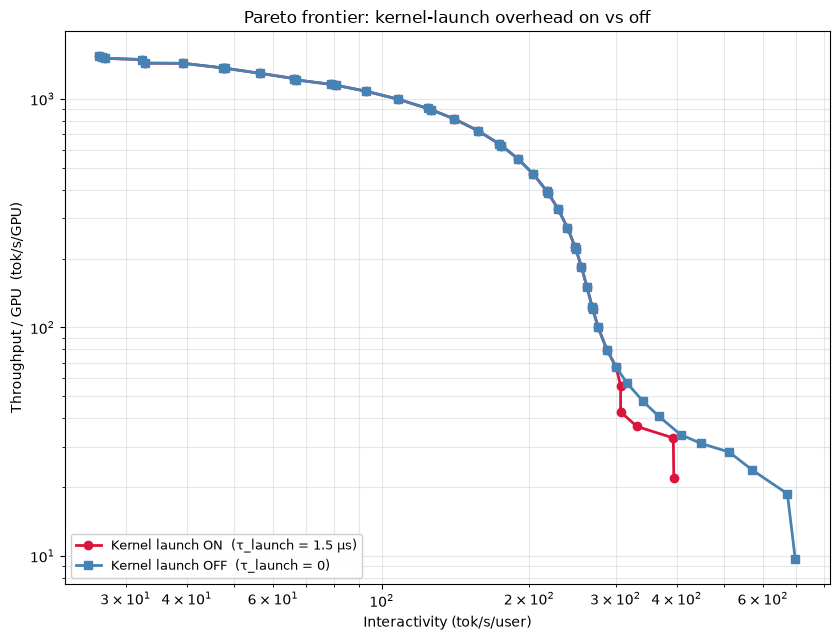

In [7]:
from dataclasses import replace


def sweep_with_breakdown(tuner_template, framework):
    """Same enumeration as §3 but stores the full LatencyResults breakdown
    on each point so we can build the table in §8 without re-running."""
    rows = []
    for part in partitions:
        try:
            mem = compute_memory(model, system, part, tuner_template, framework)
        except Exception:
            continue
        paging = KVPagingConfig(block_size=16, beam_width=1, system_overhead_GB=1.5)
        kv = compute_kv_paging(model, system, part, tuner_template, framework, mem, paging)
        b_max = int(kv.max_sequences)
        if b_max < 1:
            continue
        for B in log_spaced_batch_sizes(b_max):
            tuner = deepcopy(tuner_template)
            tuner.B_decode = B
            try:
                r = InferenceCalculator(model, system, part, tuner, framework).run()
            except Exception:
                continue
            lat = r.latency
            if lat.TPOT <= 0:
                continue
            rows.append({
                "PP": part.PP, "TP": part.TP, "EP": part.EP, "SP": part.SP, "B": B,
                "tput_per_gpu": lat.TTPS / system.num_devices,
                "interactivity": 1.0 / lat.TPOT,
                "TPOT_ms": lat.TPOT * 1e3,
                "t_compute_us": lat.t_compute * 1e6,
                "t_mem_us": lat.t_mem * 1e6,
                "t_local_us": lat.t_local * 1e6,
                "t_comm_us": lat.t_comm * 1e6,
                "t_stage_us": lat.t_stage * 1e6,
                "t_kernel_us": lat.t_kernel * 1e6,
                "t_LM_us": lat.t_LM * 1e6,
                "mb": lat.microbatch,
            })
    return rows


def frontier_rows(rows):
    """Same upper-right envelope walk as §4 but on dict rows."""
    srt = sorted(rows, key=lambda r: (-r["tput_per_gpu"], -r["interactivity"]))
    fr, best = [], -math.inf
    for r in srt:
        if r["interactivity"] > best + 1e-9:
            fr.append(r)
            best = r["interactivity"]
    fr.sort(key=lambda r: r["tput_per_gpu"])
    return fr


# Kernel-launch ON (default framework — τ_launch = 1.5 μs)
rows_on = sweep_with_breakdown(tuner_base, framework_base)
frontier_on = frontier_rows(rows_on)

# Kernel-launch OFF (τ_launch = 0 → t_kernel = 0; GPU-only roofline)
framework_off = replace(framework_base, kernel_launch_us=0.0)
rows_off = sweep_with_breakdown(tuner_base, framework_off)
frontier_off = frontier_rows(rows_off)

print(f"Kernel-on frontier:  {len(frontier_on)} pts")
print(f"Kernel-off frontier: {len(frontier_off)} pts")

# Plot the two frontiers overlaid
fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.plot([r["interactivity"] for r in frontier_on], [r["tput_per_gpu"] for r in frontier_on],
        "-o", color="crimson", lw=2.0, ms=6,
        label=f"Kernel launch ON  (τ_launch = {framework_base.kernel_launch_us:.1f} μs)")
ax.plot([r["interactivity"] for r in frontier_off], [r["tput_per_gpu"] for r in frontier_off],
        "-s", color="steelblue", lw=2.0, ms=6,
        label="Kernel launch OFF  (τ_launch = 0)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Interactivity (tok/s/user)")
ax.set_ylabel("Throughput / GPU  (tok/s/GPU)")
ax.set_title("Pareto frontier: kernel-launch overhead on vs off")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="lower left", fontsize=9, framealpha=0.95)
plt.tight_layout()
plt.savefig("assets/pareto_basic_kernel_toggle.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Per-frontier-point latency breakdown

For each kernel-on frontier point, decompose the time per token into the contributions defined in `decode.md §6.2 / §7.2`. The stage columns are per *stage pass*: one microbatch of `mb` sequences crossing one of the `PP` stages (`mb = B/PP` when the pipeline is full, `B` at `PP = 1`).

- `t_compute` — `mb · F_token,device / R_GPU` (compute roofline, §6.2)
- `t_mem` — `Σ_i (T_θ,i + mb · T_KV,i) / BW_eff,i` (multi-tier memory roofline, §6.2)
- `t_local = max(t_compute, t_mem)` — per-stage GPU roofline floor
- `t_comm` — collective communication on the stage (§5.5)
- `t_stage = t_local + max(0, t_comm − ρ · t_local)` — GPU-only per-stage time (§6.2)
- `t_kernel` — per-stage CPU/dispatch budget (§7.1); zero in the kernel-off case
- `t_LM` — LM head H→V projection after the last stage (§6.2)

A token crosses all `PP` stages, so the user-observed time per token is `t_step,user = PP · [t_stage + max(0, t_kernel − ρ_kernel · t_stage)] + t_LM`. All time columns are in microseconds.


In [8]:
cols = ["PP", "TP", "EP", "SP", "B",
        "tput_per_gpu", "TPOT_ms",
        "t_compute_us", "t_mem_us", "t_local_us",
        "t_comm_us", "t_stage_us",
        "t_kernel_us", "t_LM_us", "mb"]
INT_COLS = {"PP", "TP", "EP", "SP", "B"}


def fmt(col, value):
    """Integers as-is, TPOT to 2 decimals, every other column to 1."""
    if col in INT_COLS:
        return str(int(value))
    return f"{value:.2f}" if col == "TPOT_ms" else f"{value:.1f}"


# Plain-text table (standard library only), in order of increasing throughput.
table = [[fmt(c, row[c]) for c in cols]
         for row in sorted(frontier_on, key=lambda r: r["tput_per_gpu"])]
widths = [max(len(c), *(len(line[i]) for line in table)) for i, c in enumerate(cols)]
print("  ".join(c.rjust(w) for c, w in zip(cols, widths)))
print("  ".join("-" * w for w in widths))
for line in table:
    print("  ".join(v.rjust(w) for v, w in zip(line, widths)))

PP  TP  EP  SP     B  tput_per_gpu  TPOT_ms  t_compute_us  t_mem_us  t_local_us  t_comm_us  t_stage_us  t_kernel_us  t_LM_us      mb
--  --  --  --  ----  ------------  -------  ------------  --------  ----------  ---------  ----------  -----------  -------  ------
 1  16   1   1     1          21.9     2.53           4.6    1839.7      1839.7       98.7      1938.4       2520.0     14.7     1.0
 2  16   1   1     3          32.8     2.54           3.4    1193.5      1193.5       50.5      1244.1       1263.0     14.7     1.5
 1  16   1   1     2          36.8     3.02           9.1    2900.0      2900.0      101.5      3001.4       2520.0     14.7     2.0
 1  16   2   1     5          42.7     3.25          11.4    3000.6      3000.6      229.7      3230.2       3240.0     14.7     5.0
 1  16   4   1    13          55.5     3.25          14.8    2666.7      2666.7      478.2      3144.9       3240.0     14.7    13.0
 1  16   4   1    16          66.9     3.32          18.3    2825.0  